### Notebook for exploring Self-Conditioned Knots for Probabilistic LiDAR Hazrad Fields

In [1]:
from vedo import *
settings.default_backend = "k3d"
import numpy as np
from scipy.spatial.transform import Rotation as R
import copy

from matplotlib import pyplot as p

%load_ext autoreload
%autoreload 2
%autosave 180

Autosaving every 180 seconds


In [2]:
# Configure device (GPU if available)
import torch
from torch.utils.data import Dataset, DataLoader

# Reset default device to CPU to avoid DataLoader sampler conflicts
torch.set_default_device(None)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device name: {torch.cuda.get_device_name(0)}")
    print(f"Device count: {torch.cuda.device_count()}")
print(f"Using device: {device}")


CUDA available: True
Device name: NVIDIA GeForce GTX 1650 with Max-Q Design
Device count: 1
Using device: cuda


## Generate synthetic LiDAR data

In [3]:
from synthetic_data_generation_utils import (
    LidarProjectionModel,
    Scene,
    generate_point_cloud,
)

# 1. LiDAR Intrinsics (e.g. 32-channel, 360-degree rotation)
sensor = LidarProjectionModel(
    elevation_min=-25.0,
    elevation_max=25.0,
    num_detectors=32,
    num_azimuth=360,
    max_range=30.0,
)

# 2. Build 10x10m Enclosed Scene
scene = Scene()
wall_density = 100.0  # Solid boundaries (near-surface returns)

# --- Floor & 4 Walls (10m x 10m x 3m interior) ---
scene.add_box(center=[0.0, 0.0, -0.1], size=[10.4, 10.4, 0.2], density=wall_density, name="floor")
scene.add_box(center=[0.0, 5.1, 1.5],  size=[10.4, 0.2, 3.0],  density=wall_density, name="wall_north")
scene.add_box(center=[0.0, -5.1, 1.5], size=[10.4, 0.2, 3.0],  density=wall_density, name="wall_south")
scene.add_box(center=[5.1, 0.0, 1.5],  size=[0.2, 10.4, 3.0],  density=wall_density, name="wall_east")
scene.add_box(center=[-5.1, 0.0, 1.5], size=[0.2, 10.4, 3.0],  density=wall_density, name="wall_west")

# --- 4 Cylinders (Pillars) with density = 1.0 ---
cyl_density = 1.0
scene.add_cylinder(center=[2.5, 2.5, 1.5],   radius=0.4, height=3.0, density=cyl_density, name="pillar_NE")
scene.add_cylinder(center=[-2.5, 2.5, 1.5],  radius=0.4, height=3.0, density=cyl_density, name="pillar_NW")
scene.add_cylinder(center=[2.5, -2.5, 1.5],  radius=0.4, height=3.0, density=cyl_density, name="pillar_SE")
scene.add_cylinder(center=[-2.5, -2.5, 1.5], radius=0.4, height=3.0, density=cyl_density, name="pillar_SW")

# --- Low-Density Spheres (Porous foliage / clutter with deep volumetric penetration) ---
scene.add_sphere(center=[2.0, 0.0, 1.0],   radius=0.8,  density=0.15, name="sphere_1")
scene.add_sphere(center=[-2.0, 0.5, 1.2],  radius=0.9,  density=0.10, name="sphere_2")
scene.add_sphere(center=[0.0, 3.0, 1.5],   radius=1.1,  density=0.08, name="sphere_3")
scene.add_sphere(center=[0.0, -2.8, 1.0],  radius=0.7,  density=0.20, name="sphere_4")
scene.add_sphere(center=[3.2, -1.8, 1.3],  radius=1.0,  density=0.12, name="sphere_5")
scene.add_sphere(center=[-3.0, -2.0, 1.4], radius=0.85, density=0.18, name="sphere_6")

# 3. Generate Point Cloud with the sensor positioned at the center of the room [0, 0, 1.5]
sensor_pos = [0.0, 0.0, 1.5]
point_cloud = generate_point_cloud(
    sensor=sensor,
    scene=scene,
    sensor_position=sensor_pos,
    method="sample",             # Stochastic sampling based on return probabilities
    return_placement="volume",   # Penetrable spheres have points distributed throughout their interior
    random_seed=42,
)

print(f"Generated {len(point_cloud)} points from {sensor.total_rays} rays.")
cloud_i = np.asarray(np.shape(point_cloud.points))
print(cloud_i)

# 4. Interactive 3D visualization with vedo
plt = Plotter(N=1, axes=1, bg=(1, 1, 1), interactive=True)
disp = scene.to_vedo(alpha=0.25)
disp.append(point_cloud.to_vedo(color_by="probability", cmap="viridis", point_size=3.5))
plt.show(disp, "10x10m Enclosed Room with Pillars and Low-Density Spheres")


Generated 9281 points from 11520 rays.
[9281    3]


## generate training data from multiple viewpoints

In [4]:
import numpy as np
from synthetic_data_generation_utils import compute_look_at_rotation

def generate_orbit_poses(num_poses: int = 16, radius: float = 3.0, height: float = 1.5, target=[0.0, 0.0, 1.2]):
    """Generates N sensor poses in a circular ring facing the center."""
    angles = np.linspace(0, 2 * np.pi, num_poses, endpoint=False)
    positions = []
    rotations = []
    
    for theta in angles:
        # Sensor position along the circle
        pos = np.array([radius * np.cos(theta), radius * np.sin(theta), height])
        # Aim the sensor forward (+X in sensor local frame) toward the target point
        rot = compute_look_at_rotation(eye=pos, target=target)
        positions.append(pos)
        rotations.append(rot)
        
    return np.array(positions), np.array(rotations)


In [5]:
from synthetic_data_generation_utils import (
    LidarProjectionModel, 
    Scene, 
    trace_scene_rays,
    rays_to_plucker,
    query_cdf_along_ray,
)

# 1. Setup Intrinsics & Scene (from your notebook)
sensor = LidarProjectionModel(elevation_min=-25.0, elevation_max=25.0, num_detectors=32, num_azimuth=180)
# scene = ... (your 10x10m box room from notebook)

# 2. Get N Poses
N_poses = 12
positions, rotations = generate_orbit_poses(num_poses=N_poses, radius=3.2, height=1.4)

# 3. Collect Ray Data from all viewpoints
all_rays_o = []
all_rays_d = []
all_hit_ranges = []
all_hit_masks = []
all_gt_cdfs = []

# Distances at which to evaluate ground-truth CDF for supervision (e.g. 64 knots from 0 to 15m)
eval_knots = np.linspace(0.1, 15.0, 64)

for i in range(N_poses):
    print(i)
    pos, rot = positions[i], rotations[i]
    rays_o, rays_d = sensor.get_rays(pos, rot, flatten=True)
    
    # Trace rays to get collision / return info
    trace_results = trace_scene_rays(rays_o, rays_d, scene, max_range=sensor.max_range)
    
    for r_idx, res in enumerate(trace_results):
        hits = res["hits"]
        if len(hits) > 0:
            # First return / primary hit range
            hit_range = hits[0]["t_in"]
            hit_mask = 1.0
        else:
            hit_range = sensor.max_range
            hit_mask = 0.0
            
        all_rays_o.append(rays_o[r_idx])
        all_rays_d.append(rays_d[r_idx])
        all_hit_ranges.append(hit_range)
        all_hit_masks.append(hit_mask)
        
        # Optional: Exact continuous ground-truth CDF(t) along the ray
        gt_cdf = query_cdf_along_ray(scene, rays_o[r_idx], rays_d[r_idx], query_distances=eval_knots)
        all_gt_cdfs.append(gt_cdf)

# Stack into consolidated arrays
rays_o = np.array(all_rays_o, dtype=np.float32)       # (N_total_rays, 3)
rays_d = np.array(all_rays_d, dtype=np.float32)       # (N_total_rays, 3)
hit_ranges = np.array(all_hit_ranges, dtype=np.float32) # (N_total_rays,)
hit_masks = np.array(all_hit_masks, dtype=np.float32)   # (N_total_rays,)
gt_cdfs = np.array(all_gt_cdfs, dtype=np.float32)       # (N_total_rays, 64)

# Plücker coordinates (d, m = o x d)
plucker_d, plucker_m = rays_to_plucker(rays_o, rays_d)
plucker = np.concatenate([plucker_d, plucker_m], axis=-1).astype(np.float32)  # (N_total_rays, 6)


0
1
2
3
4
5
6
7
8
9
10
11


In [6]:
# Structure into torch dataset for training
from sck_model import LidarRayDataset, GPURayBatcher

# Define the network

In [7]:
import torch
import torch.nn as nn
from sck_model import PositionalEncoding, DeeperSCKNetwork, SCKNetwork

In [8]:
from sck_model import interpolate_cdf_to_grid, compute_sck_loss, SCKLoss

# Train Loop

### Notes: Self-Conditioned Residual Knot Flow

In true Self-Conditioning:
1. **Initial State (Round 0)**: Knots start cleanly and uniformly distributed across $[s_{\min}, s_{\max}]$ ($[0.1\text{m}, 15.0\text{m}]$).
2. **Residual Knot Flow**: Rather than re-generating absolute knot positions via an unconstrained global softmax from scratch every pass, the network outputs a local displacement field $\delta s_k = \tanh(\text{out}_0) \times d_{\max}$ that physically nudges candidate knots toward high-hazard / surface boundaries ($s^{(r+1)} = \text{sort}(s^{(r)} + \delta s)$).
3. **Self-Conditioning Refinement**: Subsequent rounds evaluate features at the updated knot positions, allowing knots to bracket sharp jumps tightly while empty regions stay naturally uniform.


In [9]:
import torch
from sck_model import train_step as sck_train_step, train_epoch, train_model

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = DeeperSCKNetwork(num_knots=32, num_rounds=2, max_displacement=0.6).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# The fixed 64 evaluation grid points (from dataset)
eval_grid = torch.linspace(0.1, 15.0, 64, device=device)
dt = (15.0 - 0.1) / (64 - 1)

def train_step(batch):
    return sck_train_step(model, optimizer, batch, eval_grid, dt=dt, device=device)

Training on cuda (69120 rays, 68 batches/epoch)...
Epoch [01/32] - Loss: 7.003195
Epoch [02/32] - Loss: 2.819547
Epoch [03/32] - Loss: 2.213651
Epoch [04/32] - Loss: 1.419196
Epoch [05/32] - Loss: 0.629594
Epoch [06/32] - Loss: 0.372551
Epoch [07/32] - Loss: 0.308246
Epoch [08/32] - Loss: 0.274008
Epoch [09/32] - Loss: 0.240651
Epoch [10/32] - Loss: 0.212699
Epoch [11/32] - Loss: 0.198679
Epoch [12/32] - Loss: 0.187741
Epoch [13/32] - Loss: 0.177762
Epoch [14/32] - Loss: 0.168636
Epoch [15/32] - Loss: 0.162299
Epoch [16/32] - Loss: 0.158633
Epoch [17/32] - Loss: 0.150335
Epoch [18/32] - Loss: 0.145230
Epoch [19/32] - Loss: 0.140297
Epoch [20/32] - Loss: 0.136870
Epoch [21/32] - Loss: 0.132205
Epoch [22/32] - Loss: 0.129143
Epoch [23/32] - Loss: 0.126286
Epoch [24/32] - Loss: 0.122551
Epoch [25/32] - Loss: 0.119976
Epoch [26/32] - Loss: 0.116693
Epoch [27/32] - Loss: 0.115206
Epoch [28/32] - Loss: 0.111313
Epoch [29/32] - Loss: 0.108896
Epoch [30/32] - Loss: 0.107761
Epoch [31/32] - Los

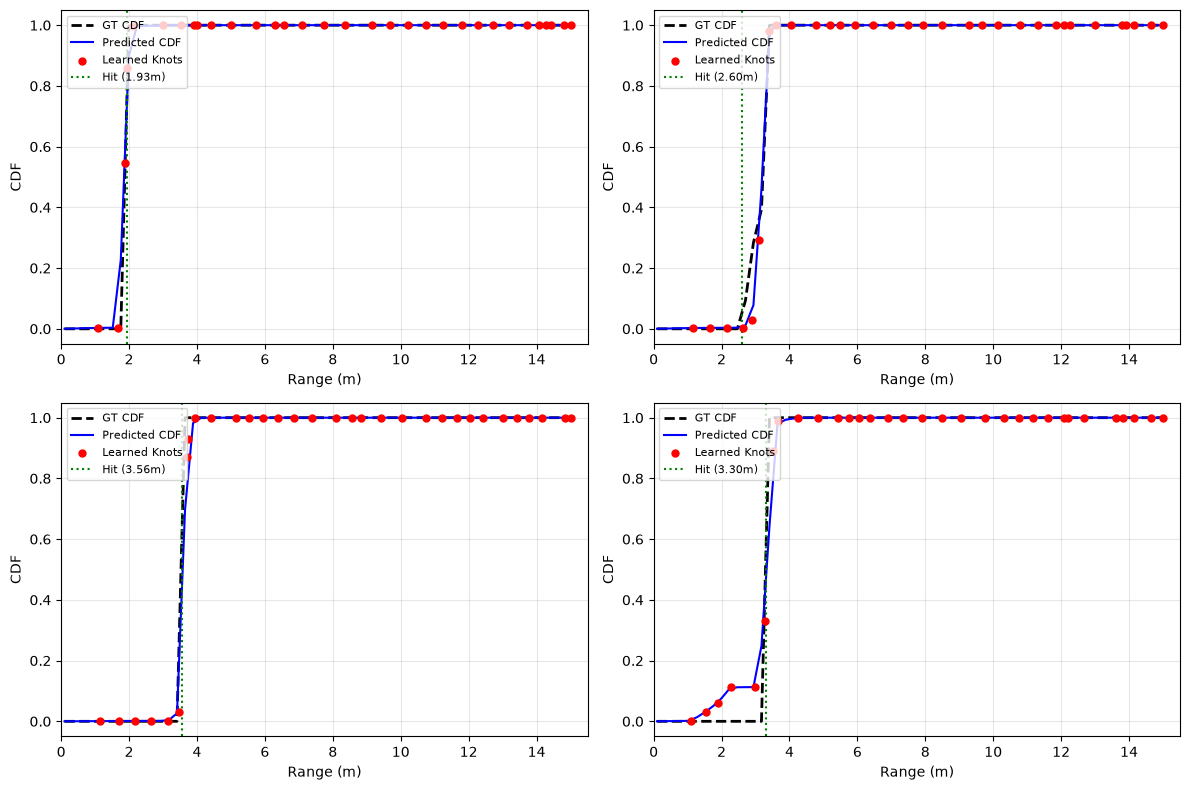

In [10]:
import matplotlib.pyplot as plt
import math

# 1. Instantiate Dataset and Fast GPU Batcher
dataset = LidarRayDataset(
    rays_o=rays_o,
    rays_d=rays_d,
    hit_ranges=hit_ranges,
    hit_masks=hit_masks,
    gt_cdfs=gt_cdfs,
)
# Direct GPU batching: zero-copy, eliminates DataLoader worker & IPC overhead
dataloader = GPURayBatcher(
    rays_o=rays_o,
    rays_d=rays_d,
    gt_cdfs=gt_cdfs,
    hit_ranges=hit_ranges,
    hit_masks=hit_masks,
    batch_size=256,
    shuffle=True,
    device=device,
)

# 2. Run Training Loop (with optional l1_weight to prevent vanishing gradient plateaus)
num_epochs = 32
history = train_model(
    model=model,
    dataloader=dataloader,
    optimizer=optimizer,
    eval_grid=eval_grid,
    num_epochs=num_epochs,
    dt=dt,
    device=device,
    augment_origin_slide=False, # Set True to enable fast vectorized GPU origin sliding!
    l1_weight=0.1,             # Composite L2 + L1 (Wasserstein-1) keeps gradients active at low error
)

# 3. Visualize Learned Knot Placements vs Ground Truth CDF
model.eval()
with torch.no_grad():
    sample_indices = [0, 50, 150, 300]
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    for ax, idx in zip(axes.flat, sample_indices):
        sample = dataset[idx]
        o = sample["ray_o"].unsqueeze(0).to(device)
        d = sample["ray_d"].unsqueeze(0).to(device)
        gt = sample["gt_cdf"].cpu().numpy()

        s_knots, c_knots, _ = model(o, d)
        s_k = s_knots[0].cpu().numpy()
        c_k = c_knots[0].cpu().numpy()
        pred_interp = interpolate_cdf_to_grid(s_knots, c_knots, eval_grid)[0].cpu().numpy()
        eval_pts = eval_grid.cpu().numpy()

        ax.plot(eval_pts, gt, 'k--', label='GT CDF', linewidth=2)
        ax.plot(eval_pts, pred_interp, 'b-', label='Predicted CDF')
        ax.scatter(s_k, c_k, color='red', s=25, zorder=5, label='Learned Knots')
        if sample["hit_mask"] > 0:
            ax.axvline(sample["hit_range"].item(), color='green', linestyle=':', label=f'Hit ({sample["hit_range"]:.2f}m)')

        ax.set_xlim(0.0, 15.5)
        ax.set_ylim(-0.05, 1.05)
        ax.set_xlabel("Range (m)")
        ax.set_ylabel("CDF")
        ax.legend(loc="upper left", fontsize=8)
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

# Make cloud at novel position

In [17]:
import torch
import numpy as np
from synthetic_data_generation_utils import PointCloud
from vedo import Plotter
from sck_model import generate_point_cloud_from_network

# ==============================================================================
# Execute Inference and Draw
# ==============================================================================

# 1. Generate point cloud with the sensor placed at room center [0, 0, 1.5]
pred_cloud = generate_point_cloud_from_network(
    model=model,
    sensor=sensor,
    sensor_position=[0.0, 0.0, 1.5],
    # method='sample', #"threshold",  # or "sample"
    method="threshold",  # or "sample"
    threshold=0.1,
    device=device,
)

# 2. 3D interactive visualization with Vedo (overlaid on scene geometry)
plt_vedo = Plotter(N=1, axes=1, bg=(1, 1, 1), interactive=True)
disp = scene.to_vedo(alpha=0.15)

disp.append(pred_cloud.to_vedo(color_by="range", cmap="plasma", point_size=3.5))
plt_vedo.show(disp, "Network Reconstructed Point Cloud")

In [ ]:
print("Model device:", next(model.parameters()).device)
print(f"Allocated VRAM: {torch.cuda.memory_allocated() / (1024**2):.2f} MB")